In [2]:
from pathlib import Path

# Le notebook s'exécute depuis notebooks/, donc on remonte d'un niveau
# pour trouver la racine du projet.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

PDF_PATH   = ROOT / "data" / "attention_is_all_you_need.pdf"
OUTPUT_DIR = ROOT / "resultats_pdf"
TEXT_DIR   = OUTPUT_DIR / "textes"
IMAGE_DIR  = OUTPUT_DIR / "images"

if not PDF_PATH.is_file():
    raise FileNotFoundError(f"PDF introuvable : {PDF_PATH}")

TEXT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
print("PDF :", PDF_PATH)

PDF : c:\Users\bouho\Desktop\TP3_Rag\TP3_Rag\data\attention_is_all_you_need.pdf


In [4]:
import pymupdf

textes = []
nombre_images = 0

with pymupdf.open(PDF_PATH) as document:
    for numero_page, page in enumerate(document, start=1):

        # --- Texte de la page ---
        texte = page.get_text("text", sort=True)
        (TEXT_DIR / f"page_{numero_page:03d}.txt").write_text(texte, encoding="utf-8")
        textes.append(f"===== PAGE {numero_page} =====\n\n{texte}")

        # --- Images intégrées dans la page ---
        images_vues = set()
        for info in page.get_images(full=True):
            xref = info[0]
            if xref in images_vues:
                continue
            images_vues.add(xref)

            image = document.extract_image(xref)
            if not image:
                continue
            fichier = IMAGE_DIR / f"page_{numero_page:03d}_image_{xref}.{image['ext']}"
            fichier.write_bytes(image["image"])
            nombre_images += 1

(OUTPUT_DIR / "texte_complet.txt").write_text("\n\n".join(textes), encoding="utf-8")

print(f"Pages : {len(textes)} | Images : {nombre_images}")

Pages : 15 | Images : 3


                     Provided proper attribution is provided, Google hereby grants permission to
                     reproduce the tables and figures in this paper solely for use in journalistic or
                                                     scholarly works.


                          Attention Is All You Need





                         Ashish Vaswani∗      Noam Shazeer∗       Niki Parmar∗     Jakob Uszkoreit∗2023                     Google Brain          Google Brain       Google Research     Google Research
Aug               avaswani@google.comLlion Jones∗      noam@google.comAidan N. Gomez∗†nikip@google.comŁukaszusz@google.comKaiser∗
2                    Google Research          University of Toronto              Google Brain
                      llion@google.com     aida
page_003_image_128.png


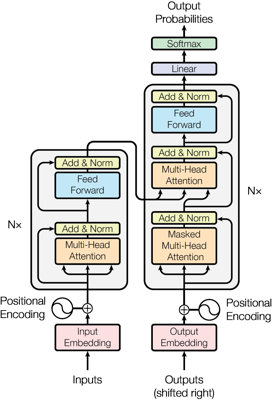

page_004_image_182.png


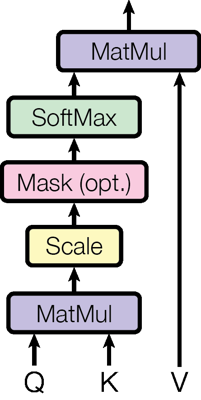

page_004_image_183.png


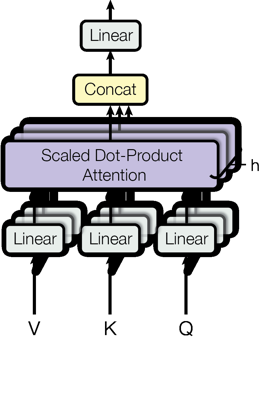

In [5]:
from PIL import Image
from IPython.display import display

print((TEXT_DIR / "page_001.txt").read_text(encoding="utf-8")[:800])

for fichier in sorted(IMAGE_DIR.iterdir()):
    print(fichier.name)
    with Image.open(fichier) as img:
        apercu = img.copy()
        apercu.thumbnail((400, 400))
        display(apercu)